# Figures and numbers of the paper

Run this notebook from top to bottom. It needs no network access and only uses
the bundled corpus and the tables in `results/`. In order, it

1. extracts the commands that the two LLM agents executed (RQ4) and writes them
   to `results/agents/`,
2. checks how much larger corpora could change the reach (threats to validity)
   and writes `results/analysis/a8_file_subsampling.csv`,
3. draws Figures 1 to 4 and Table II into `results/figures/`,
4. prints the numbers quoted in the paper, and
5. recomputes the tables in `results/analysis/` from the foundation tables as a
   check.

In [1]:
from pathlib import Path
import collections
import csv
import glob
import json
import re

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

# The repository root is the first parent folder that contains results/analysis.
BASE = Path.cwd()
while not (BASE / 'results' / 'analysis').exists() and BASE != BASE.parent:
    BASE = BASE.parent
AN = BASE / 'results' / 'analysis'
FIGURES = BASE / 'results' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

DS = ['gnu', 'git', 'ci']
DSL = {'gnu': 'GNU utilities', 'git': 'Git', 'ci': 'CI tooling'}
DSS = {'gnu': 'GNU', 'git': 'Git', 'ci': 'CI'}
POP = {'human': 'developer', 'llm': 'LLM', 'kernel': 'kernel'}


def load(name):
    return pd.read_csv(AN / name)


# One row per option use, with empty options for invocations without options.
inv = load('invocations_long.csv')
gt = load('groundtruth_long.csv')
# Option uses that match an option documented for their unit.
used = inv[inv.option.notna() & (inv.option != '')].merge(gt, on=['dataset', 'unit', 'option'])
cov = load('a1_population_coverage.csv')
reach = {(r.dataset, r.population): r.reach_pct for r in cov.itertuples()}
nopt = {(r.dataset, r.population): int(r.opts_used) for r in cov.itertuples()}


def option_set(d, p):
    s = used[(used.dataset == d) & (used.population == p)]
    return set(zip(s.unit, s.option))

## 1. Commands executed by the LLM agents (RQ4)

The trajectories are in `corpus/agents/`: 600 SWE-agent runs (570 with Llama 70B
and 30 with Llama 8B) in `raw/`, downloaded by `08-pilot-agent-trajectories.sh`,
and 600 DeepSWE-Agent runs with Kimi K2 in `raw_kimi/`. Both are parsed like the
static corpora (Section III-E). Each executed command line is split at `|`, `||`,
`&&`, and `;`, every command whose program is one of the 118 GNU units is kept,
and its options are normalised (`=value` removed, short option clusters split
except for `find` and `stty`) and checked against the ground truth of the unit.

In [2]:
RAW_SWE = BASE / 'corpus' / 'agents' / 'raw'
RAW_KIMI = BASE / 'corpus' / 'agents' / 'raw_kimi'
GT_DIR = BASE / 'data' / 'groundtruth' / 'gnu'
AGENTS = BASE / 'results' / 'agents'

GT = {p.stem: {l.strip() for l in p.open() if l.strip()} for p in GT_DIR.glob('*.txt')}
GT_SIZE = sum(len(v) for v in GT.values())
TRAILING = re.compile(r'["\'`\\);:,.\]}]+$')


def swe_agent_commands():
    """Lines of the last fenced block of every assistant turn (as 08-*.sh)."""
    for f in sorted(glob.glob(str(RAW_SWE / 'rows_*.json'))):
        for row in json.load(open(f))['rows']:
            r = row['row']
            for turn in r.get('trajectory') or []:
                if turn.get('role') != 'ai':
                    continue
                parts = (turn.get('text') or '').split('```')
                if len(parts) < 3:
                    continue
                block = re.sub(r'^[a-z]*\n', '', parts[-2]).replace('\t', ' ')
                for line in block.split('\n'):
                    line = line.strip(' \t\r')
                    if line:
                        yield 'llama-70b', r['instance_id'], line


def kimi_commands():
    """Lines of the command parameter of every execute_bash call."""
    for f in sorted(glob.glob(str(RAW_KIMI / 'rows_*.json'))):
        for row in json.load(open(f))['rows']:
            run = f"kimi-{row['row_idx']}"
            for m in row['row']['messages']:
                if m['role'] != 'assistant':
                    continue
                for blk in re.findall(r'<function=execute_bash>(.*?)</function>', m['content'] or '', re.S):
                    cmd = re.search(r'<parameter=command>(.*?)</parameter>', blk, re.S)
                    if not cmd:
                        continue
                    for line in cmd.group(1).split('\n'):
                        line = line.strip()
                        if line:
                            yield 'kimi-k2', run, line


def invocations(line):
    """GNU-unit invocations in one command line, with their options."""
    line = re.sub(r'2>[^ ]*', '', line)
    for seg in re.split(r'\|\||&&|\||;', line):
        tok = seg.split()
        if not tok:
            continue
        c = 1 if tok[0] in ('sudo', 'env', 'command') else 0
        if c >= len(tok):
            continue
        unit = re.sub(r'^.*/', '', tok[c])
        if unit not in GT:
            continue
        opts = []
        for t in tok[c + 1:]:
            if t == '--':
                break
            if not t.startswith('-'):
                continue
            t = TRAILING.sub('', re.sub(r'=.*$', '', t))
            if not re.match(r'^--?[a-zA-Z]', t):
                continue
            if re.fullmatch(r'-[a-zA-Z]{2,}', t) and unit not in ('find', 'stty'):
                opts += ['-' + ch for ch in t[1:]]
            else:
                opts.append(t)
        yield unit, opts


def analyse_agents():
    AGENTS.mkdir(parents=True, exist_ok=True)
    rows = [(agent, run, unit, opts)
            for gen in (swe_agent_commands, kimi_commands)
            for agent, run, line in gen()
            for unit, opts in invocations(line)]
    with open(AGENTS / 'agent_invocations.csv', 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['agent', 'run', 'unit', 'options'])
        w.writerows((a, r, u, ' '.join(o)) for a, r, u, o in rows)

    counts = collections.Counter((a, u, o) for a, _, u, opts in rows for o in opts)
    with open(AGENTS / 'agent_option_counts.csv', 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['agent', 'unit', 'option', 'uses', 'valid'])
        for (a, u, o), n in sorted(counts.items(), key=lambda kv: (kv[0][0], -kv[1], kv[0][1], kv[0][2])):
            w.writerow([a, u, o, n, int(o in GT[u])])

    with open(AGENTS / 'agent_pilot_summary.csv', 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['agent', 'dataset', 'invocations', 'pct_zero_option', 'mean_opts_per_call',
                    'distinct_options', 'invalid_distinct', 'reach_pct'])
        for agent in ('llama-70b', 'kimi-k2'):
            inv = [o for a, _, _, o in rows if a == agent]
            opts = {(u, o) for a, _, u, os_ in rows if a == agent for o in os_}
            valid = {(u, o) for u, o in opts if o in GT[u]}
            w.writerow([agent, 'gnu', len(inv), f'{100 * sum(not o for o in inv) / len(inv):.2f}',
                        f'{sum(len(o) for o in inv) / len(inv):.3f}', len(opts), len(opts) - len(valid),
                        f'{100 * len(valid) / GT_SIZE:.2f}'])
    print(open(AGENTS / 'agent_pilot_summary.csv').read(), end='')


analyse_agents()

agent,dataset,invocations,pct_zero_option,mean_opts_per_call,distinct_options,invalid_distinct,reach_pct
llama-70b,gnu,1802,29.36,0.719,24,5,0.70
kimi-k2,gnu,14370,28.18,1.298,64,26,1.40


## 2. Corpus size check (threats to validity)

For each corpus, we draw 500 random samples (without replacement, fixed seed) of
50%, 75%, and 90% of its files and count how many documented options the samples
reach on average. Only files with at least one invocation of a studied unit are
counted. If samples of 90% of the files already reach almost all options of the
full corpus, more files would mostly repeat options that are already used.

In [3]:
def subsample_files(draws=500, seed=7, fractions=(0.5, 0.75, 0.9)):
    rng = np.random.default_rng(seed)
    rows = []
    corpora = {'gnu': ('human', 'llm', 'kernel'), 'git': ('human', 'llm'), 'ci': ('human', 'llm')}
    for d, pops in corpora.items():
        for p in pops:
            files = inv[(inv.dataset == d) & (inv.population == p)].file.unique()
            sub = used[(used.dataset == d) & (used.population == p)]
            opts = {f: set(zip(g.unit, g.option)) for f, g in sub.groupby('file')}
            full = len(set().union(*opts.values()))
            row = {'dataset': d, 'population': p, 'files': len(files), 'options_100': full}
            for frac in fractions:
                k = int(round(frac * len(files)))
                reached = [len(set().union(*(opts.get(f, set()) for f in rng.choice(files, k, replace=False))))
                           for _ in range(draws)]
                row[f'options_{int(frac * 100)}'] = round(float(np.mean(reached)), 1)
            row['gain_last10_pct'] = round(100 * (full - row['options_90']) / full, 1)
            rows.append(row)
    out = pd.DataFrame(rows)[['dataset', 'population', 'files', 'options_50', 'options_75',
                              'options_90', 'options_100', 'gain_last10_pct']]
    out.to_csv(AN / 'a8_file_subsampling.csv', index=False)
    return out


subsample_files()

,dataset,population,files,options_50,options_75,options_90,options_100,gain_last10_pct
0,gnu,human,242,107.2,128.3,139.6,146,4.4
1,gnu,llm,290,113.1,133.3,142.4,148,3.8
2,gnu,kernel,925,138.3,166.9,181.6,191,4.9
3,git,human,174,66.0,83.0,91.9,97,5.3
4,git,llm,305,101.1,121.8,131.7,137,3.9
5,ci,human,31,12.0,16.0,18.6,20,7.0
6,ci,llm,60,12.3,16.9,19.4,21,7.6


## 3. Figures 1 to 4 and Table II

The figures only read the tables in `results/analysis/` and `results/agents/`.
Corpora are labelled developer, LLM, and kernel. In Figure 1b, Git is marked n/a
because the Git extractor only records invocations that carry an option. In
Figure 2b, the GNU bar also shows the options that only the kernel corpus uses.

In [4]:
STYLE_LARGE = {
    'font.family': 'DejaVu Sans',
    'font.size': 12.5,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'axes.labelsize': 12, 'axes.labelcolor': '#222222',
    'axes.edgecolor': '#9aa0a6', 'axes.linewidth': 0.9,
    'xtick.color': '#3c4043', 'ytick.color': '#3c4043',
    'xtick.labelsize': 11.5, 'ytick.labelsize': 11.5,
    'text.color': '#202124',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 130, 'savefig.bbox': 'tight', 'pdf.fonttype': 42,
}
C = {'human': '#0072B2', 'llm': '#D55E00', 'kernel': '#009E73'}
LAB = {'human': 'developer', 'llm': 'LLM', 'kernel': 'kernel'}
USED = '#2f7df6'
TRACK = '#eef1f5'
SHARED = '#6b7280'

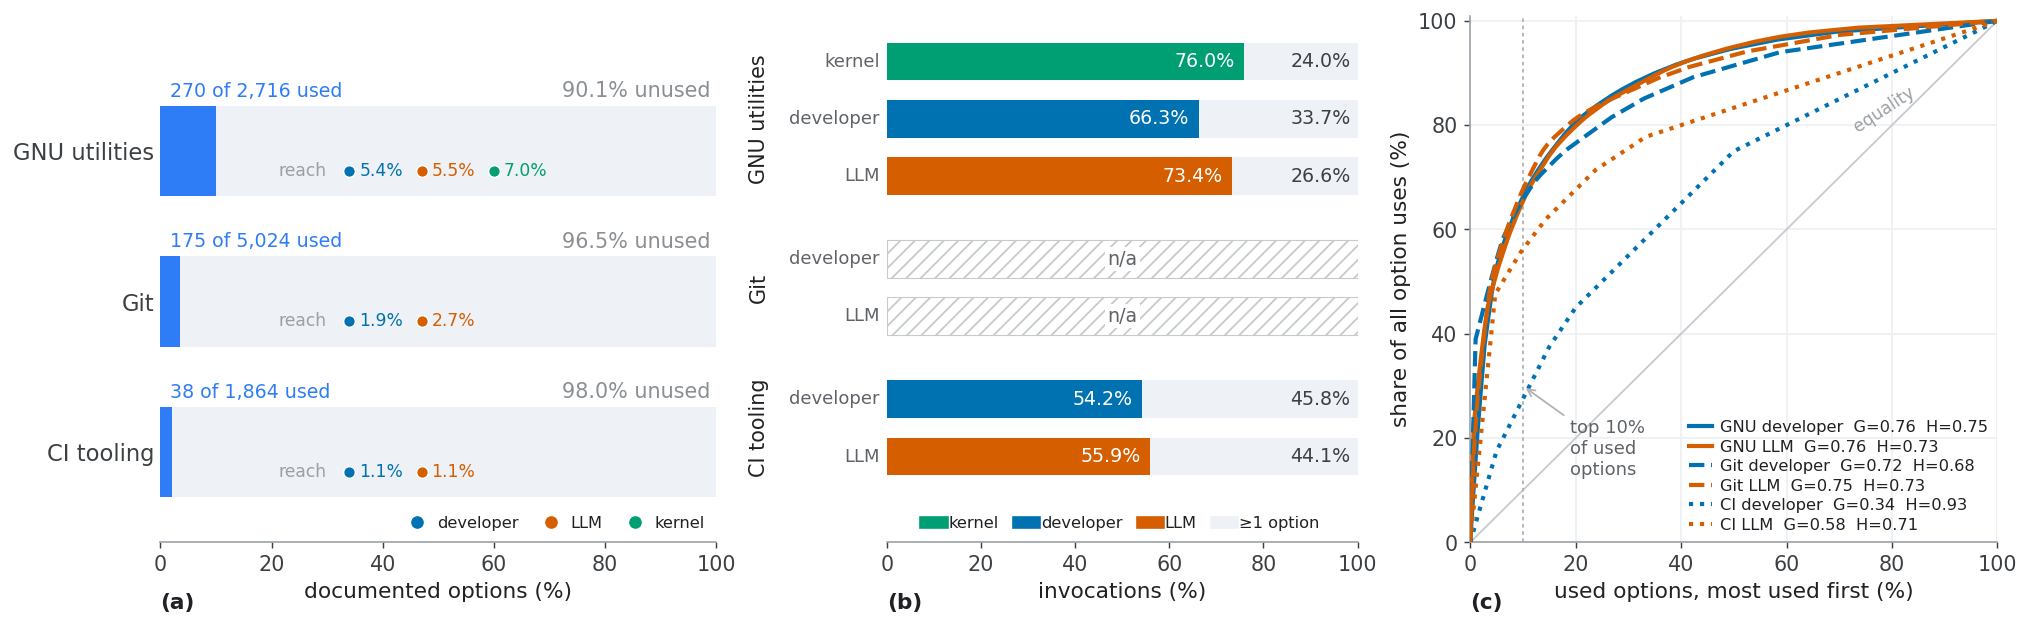

In [5]:
def fig_rq1():
    plt.rcParams.update(STYLE_LARGE)
    summ = load('a1_dataset_summary.csv').set_index('dataset')
    dist = load('a7_distribution.csv')
    conc = load('a7_concentration.csv')
    counts = used.groupby(['dataset', 'population', 'unit', 'option']).size().reset_index(name='uses')
    ent = {(r.dataset, r.population): r.norm_entropy for r in conc.itertuples()}

    def lorenz(c):
        c = np.sort(np.asarray(c, float))[::-1]
        y = np.concatenate([[0], np.cumsum(c) / c.sum()])
        return np.linspace(0, 1, len(y)) * 100, y * 100

    def gini(c):
        c = np.sort(np.asarray(c, float))
        n = len(c)
        return (2 * np.sum(np.arange(1, n + 1) * c) / (n * c.sum())) - (n + 1) / n

    fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(15.5, 4.7),
                                        gridspec_kw={'width_ratios': [1.18, 1.0, 1.12]})
    fig.set_constrained_layout(True)

    # (a) saturation and per-corpus reach
    reach_order = {'gnu': ['human', 'llm', 'kernel'], 'git': ['human', 'llm'], 'ci': ['human', 'llm']}
    y = np.arange(len(DS))[::-1]
    for yi, d in zip(y, DS):
        used_pct = 100 - summ.loc[d, 'never_pct']
        n_used, n_tot = int(summ.loc[d, 'opts_union']), int(summ.loc[d, 'gt_options'])
        axA.barh(yi, 100, color=TRACK, edgecolor='none', height=0.60, zorder=1)
        axA.barh(yi, used_pct, color=USED, edgecolor='none', height=0.60, zorder=2)
        axA.text(99, yi + 0.40, f"{summ.loc[d, 'never_pct']:.1f}% unused",
                 ha='right', va='center', fontsize=11.5, color='#8a8f94', zorder=3)
        axA.text(1.8, yi + 0.40, f"{n_used} of {n_tot:,} used",
                 ha='left', va='center', fontsize=10.5, color=USED, zorder=3)
        axA.text(30, yi - 0.13, 'reach', ha='right', va='center', fontsize=9.5, color='#9aa0a6')
        xx = 34
        for p in reach_order[d]:
            axA.scatter(xx, yi - 0.13, s=42, color=C[p], edgecolor='white', linewidth=0.8, zorder=3)
            axA.text(xx + 1.8, yi - 0.13, f"{reach[(d, p)]:.1f}%", ha='left', va='center',
                     fontsize=9.5, color=C[p], zorder=3)
            xx += 13
    axA.set_yticks(y)
    axA.set_yticklabels([DSL[d] for d in DS], fontsize=12.5)
    axA.set_xlim(0, 100)
    axA.set_xlabel('documented options (%)')
    axA.set_ylim(-0.6, len(DS) - 0.1)
    axA.text(0.0, -0.115, '(a)', transform=axA.transAxes, fontsize=12, fontweight='bold', va='center')
    axA.tick_params(axis='y', length=0)
    axA.spines['left'].set_visible(False)
    axA.legend(handles=[Line2D([0], [0], marker='o', color='w', markerfacecolor=C[k],
                               markeredgecolor='white', markersize=8, label=LAB[k])
                        for k in ('human', 'llm', 'kernel')],
               frameon=False, fontsize=9, loc='lower right', ncol=3,
               handletextpad=0.2, columnspacing=1.0, borderpad=0.2)

    # (b) share of invocations with no option vs. at least one option
    order_b = {'gnu': ['kernel', 'human', 'llm'], 'git': ['human', 'llm'], 'ci': ['human', 'llm']}
    rows = [(d, p, dist[(dist.dataset == d) & (dist.population == p)].iloc[0]['pct_zero_option'])
            for d in DS for p in order_b[d]]
    ypos, ylab, centers = [], [], {}
    yy = 0
    for d in DS:
        start = yy
        for p in order_b[d]:
            ypos.append(yy)
            ylab.append(LAB[p])
            yy += 1
        centers[d] = (start + yy - 1) / 2
        yy += 0.45
    ypos = np.array(ypos)
    for (d, p, z), yi, lab in zip(rows, ypos, ylab):
        axB.text(-1.5, yi, lab, va='center', ha='right', fontsize=10, color='#5f6368', zorder=3)
        if d == 'git':
            # Zero-option Git calls are not recorded by the extractor.
            axB.barh(yi, 100, height=0.66, color='white', edgecolor='#c7cacd', hatch='///',
                     linewidth=0.6, zorder=1)
            axB.text(50, yi, 'n/a', va='center', ha='center', fontsize=10.5, color='#5f6368',
                     zorder=3, bbox=dict(facecolor='white', edgecolor='none', pad=1.5))
            continue
        axB.barh(yi, z, height=0.66, color=C[p], edgecolor='none', zorder=2)
        axB.barh(yi, 100 - z, left=z, height=0.66, color=TRACK, edgecolor='none', zorder=1)
        axB.text(z - 2, yi, f"{z:.1f}%", va='center', ha='right', fontsize=10.5, color='white', zorder=3)
        axB.text(98.5, yi, f"{100 - z:.1f}%", va='center', ha='right', fontsize=10.5,
                 color='#3c4043', zorder=3)
    for d in DS:
        axB.text(-25, centers[d], DSL[d], va='center', ha='right', fontsize=11.5,
                 color='#202124', rotation=90)
    axB.set_yticks([])
    axB.set_ylim(ypos.min() - 0.8, ypos.max() + 1.5)
    axB.invert_yaxis()
    axB.set_xlim(0, 100)
    axB.set_xlabel('invocations (%)')
    axB.text(0.0, -0.115, '(b)', transform=axB.transAxes, fontsize=12, fontweight='bold', va='center')
    axB.spines['left'].set_visible(False)
    axB.tick_params(axis='y', length=0)
    axB.legend(handles=[Line2D([0], [0], color=C['kernel'], lw=7, label='kernel'),
                        Line2D([0], [0], color=C['human'], lw=7, label='developer'),
                        Line2D([0], [0], color=C['llm'], lw=7, label='LLM'),
                        Line2D([0], [0], color=TRACK, lw=7, label='\u22651 option')],
               frameon=False, fontsize=9, loc='lower center', ncol=4, handlelength=1.0,
               handletextpad=0.4, columnspacing=1.2, borderpad=0.2)

    # (c) concentration: Lorenz curves with Gini and normalised entropy
    lsty = {'gnu': '-', 'git': '--', 'ci': ':'}
    axC.plot([0, 100], [0, 100], color='#c7cacd', lw=1, zorder=1)
    axC.text(72, 78, 'equality', rotation=33, color='#9aa0a6', fontsize=9.5, va='bottom')
    for d in DS:
        for p in ('human', 'llm'):
            c = counts[(counts.dataset == d) & (counts.population == p)]['uses']
            x, yv = lorenz(c)
            axC.plot(x, yv, lsty[d], color=C[p], lw=2.3, zorder=3,
                     label=f"{DSS[d]} {LAB[p]}  G={gini(c):.2f}  H={ent[(d, p)]:.2f}")
    axC.axvline(10, color='#b0b3b8', lw=1, ls=(0, (2, 2)), zorder=2)
    axC.annotate('top 10% \nof used\noptions', xy=(10, 30), xytext=(19, 13), fontsize=10,
                 color='#5f6368', ha='left', arrowprops=dict(arrowstyle='->', color='#b0b3b8', lw=1))
    axC.set_xlim(0, 100)
    axC.set_ylim(0, 101)
    axC.set_xlabel('used options, most used first (%)')
    axC.set_ylabel('share of all option uses (%)')
    axC.text(0.0, -0.115, '(c)', transform=axC.transAxes, fontsize=12, fontweight='bold', va='center')
    axC.legend(frameon=False, fontsize=9, loc='lower right', handlelength=1.4,
               handletextpad=0.5, labelspacing=0.28, borderpad=0.1)
    axC.grid(color='#eef0f1', lw=1, zorder=0)
    axC.set_axisbelow(True)

    fig.savefig(FIGURES / 'rq1_saturation.pdf')


fig_rq1()

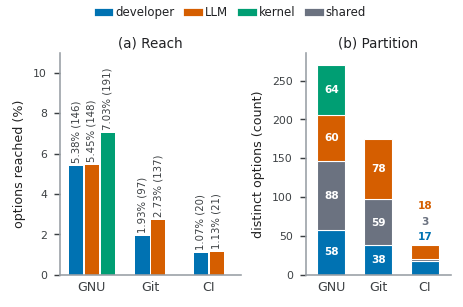

In [6]:
def fig_rq2():
    """Fig. 2: reach of each corpus (a) and partition of the used options (b)."""
    plt.rcParams.update(STYLE_LARGE)
    corpora = {'gnu': ['human', 'llm', 'kernel'], 'git': ['human', 'llm'], 'ci': ['human', 'llm']}
    part = {}
    for d in DS:
        H, M = option_set(d, 'human'), option_set(d, 'llm')
        assert (len(H), len(M)) == (nopt[(d, 'human')], nopt[(d, 'llm')])
        segs = [('human', len(H - M)), ('shared', len(H & M)), ('llm', len(M - H))]
        if d == 'gnu':
            segs.append(('kernel', len(option_set(d, 'kernel') - (H | M))))
        part[d] = segs
    col = {'human': C['human'], 'shared': SHARED, 'llm': C['llm'], 'kernel': C['kernel']}

    fig, (axA, axB) = plt.subplots(1, 2, figsize=(3.45, 2.25), gridspec_kw={'width_ratios': [1.25, 1]})
    fig.set_constrained_layout(True)
    x = np.arange(len(DS)).astype(float)

    # (a) reach, grouped vertical bars
    bw = 0.27
    for xi, d in zip(x, DS):
        coh = corpora[d]
        offs = (np.arange(len(coh)) - (len(coh) - 1) / 2) * bw
        for p, off in zip(coh, offs):
            r = reach[(d, p)]
            axA.bar(xi + off, r, width=bw * 0.9, color=C[p], edgecolor='none', zorder=2)
            axA.text(xi + off, r + 0.15, f"{r:.2f}% ({nopt[(d, p)]})", ha='center', va='bottom',
                     rotation=90, fontsize=5.6, color='#3c4043', zorder=3)
    axA.set_ylim(0, 11)
    axA.set_ylabel('options reached (%)', fontsize=7)
    axA.set_title('(a) Reach', fontsize=7.5, pad=3, fontweight='normal')

    # (b) partition, stacked vertical bars
    tot = max(sum(w for _, w in part[d]) for d in DS)
    for xi, d in zip(x, DS):
        bottom = 0
        small = []
        for name, w in part[d]:
            axB.bar(xi, w, bottom=bottom, width=0.6, color=col[name], edgecolor='white', linewidth=0.6, zorder=2)
            if w >= 0.07 * tot:
                axB.text(xi, bottom + w / 2, f"{w}", ha='center', va='center', fontsize=5.8,
                         color='white', fontweight='bold', zorder=3)
            else:
                small.append((name, w))
            bottom += w
        for k, (name, w) in enumerate(small):
            axB.text(xi, bottom + 4 + k * 0.075 * tot, f"{w}", ha='center', va='bottom', fontsize=5.8,
                     color=col[name], fontweight='bold', zorder=3)
    axB.set_ylim(0, tot * 1.06)
    axB.set_ylabel('distinct options (count)', fontsize=7)
    axB.set_title('(b) Partition', fontsize=7.5, pad=3, fontweight='normal')

    for ax in (axA, axB):
        ax.set_xticks(x)
        ax.set_xticklabels([DSS[d] for d in DS], fontsize=7)
        ax.tick_params(axis='y', labelsize=6)
        ax.tick_params(axis='x', length=0)
        ax.set_xlim(-0.55, len(DS) - 0.45)
    fig.legend(handles=[Line2D([0], [0], color=col[k], lw=4, label=lab) for k, lab in
                        (('human', 'developer'), ('llm', 'LLM'), ('kernel', 'kernel'), ('shared', 'shared'))],
               frameon=False, fontsize=6.5, loc='outside upper center', ncol=4,
               handlelength=1.0, handletextpad=0.5, columnspacing=1.1, borderpad=0.0)
    fig.savefig(FIGURES / 'rq2_reach_partition.pdf')


fig_rq2()

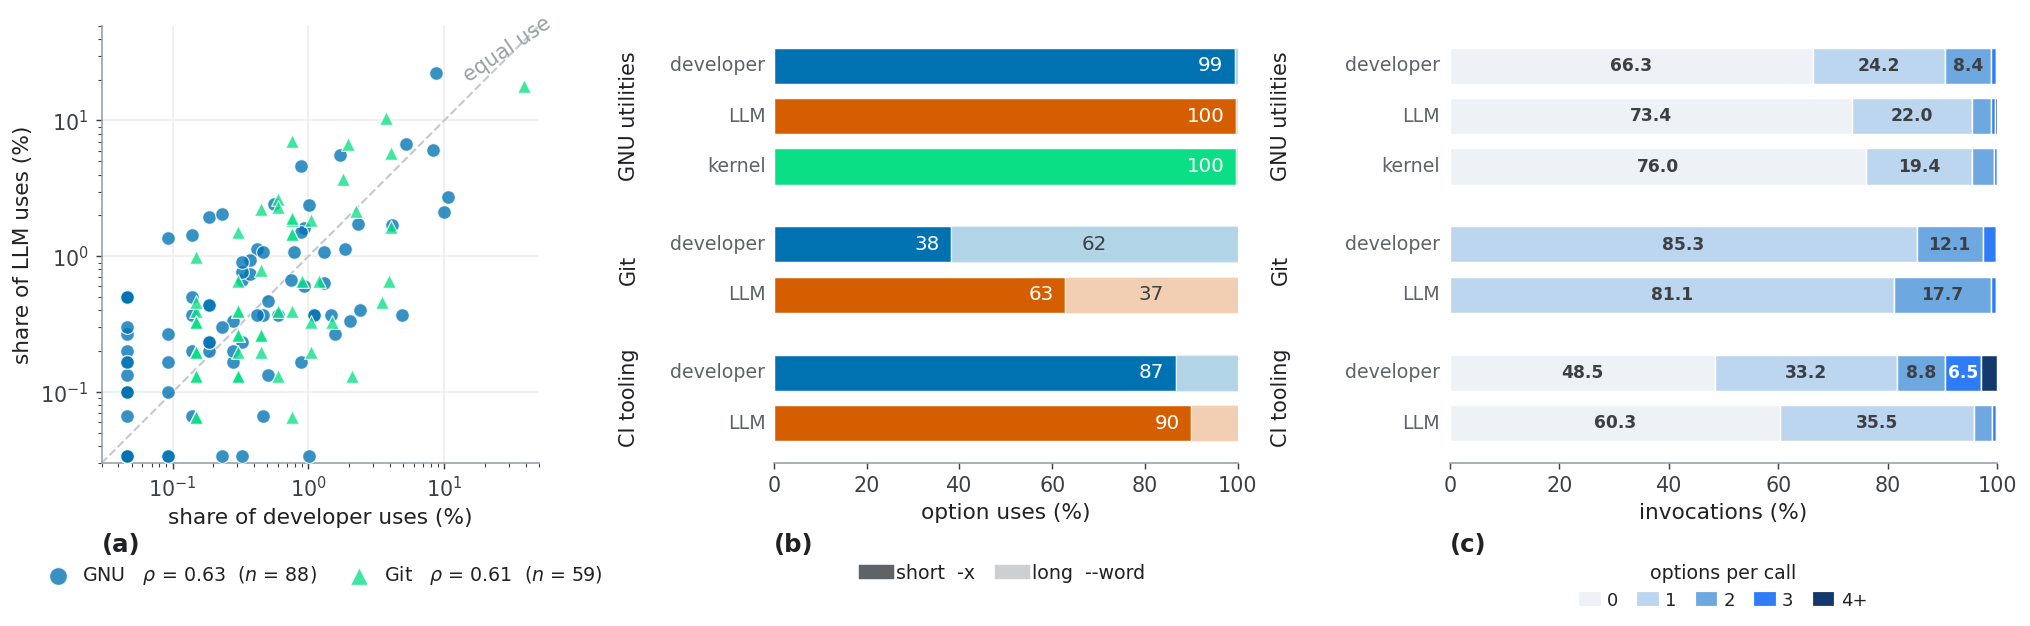

In [7]:
def fig_rq3():
    plt.rcParams.update(STYLE_LARGE)
    ck = dict(C, kernel='#0ADF86')
    pop = load('a2_option_popularity.csv')
    form = load('a4_form_preference.csv')
    rho = {}
    for d in DS:
        g = pop[(pop.dataset == d) & (pop.status == 'shared')]
        rho[d] = (spearmanr(g['human_pct'], g['llm_pct'])[0], len(g))

    buckets = ['0', '1', '2', '3', '4+']

    def bucketise(c):
        c = pd.Series(c).astype(int)
        raw = [(c == 0).sum(), (c == 1).sum(), (c == 2).sum(), (c == 3).sum(), (c >= 4).sum()]
        return np.array([100.0 * v / len(c) for v in raw])

    res = BASE / 'results'
    depth = {
        ('gnu', 'human'): bucketise(pd.read_csv(res / 'gnu/human_invocations.csv')['option_count']),
        ('gnu', 'llm'): bucketise(pd.read_csv(res / 'gnu/llm_invocations.csv')['option_count']),
        ('gnu', 'kernel'): bucketise(pd.read_csv(res / 'gnu/coreutils_invocations.csv')['option_count']),
        ('ci', 'human'): bucketise(pd.read_csv(res / 'ci/human_ci_invocations.csv')['option_count']),
        ('ci', 'llm'): bucketise(pd.read_csv(res / 'ci/llm_ci_invocations.csv')['option_count']),
    }
    gitraw = pd.read_csv(BASE / 'results/git/git_invocations_raw.csv')
    for grp in ('human', 'llm'):
        depth[('git', grp)] = bucketise(gitraw.loc[gitraw.group == grp, 'num_options'])

    depth_col = ['#eef1f5', '#bcd6f0', '#6ea8e0', '#2f7df6', '#13386b']
    mk = {'gnu': ('o', ck['human']), 'git': ('^', ck['kernel'])}

    def panel_letter(ax, s):
        ax.text(0.0, -0.16, s, transform=ax.transAxes, fontsize=13.5, fontweight='bold', va='top')

    def grouped_layout(order):
        ypos, ylab, rows, centers = [], [], [], {}
        yy = 0.0
        for d in DS:
            start = yy
            for p in order[d]:
                ypos.append(yy)
                ylab.append(LAB[p])
                rows.append((d, p))
                yy += 1
            centers[d] = (start + yy - 1) / 2
            yy += 0.55
        return np.array(ypos), ylab, rows, centers

    fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(15.5, 4.7),
                                        gridspec_kw={'width_ratios': [1.12, 1.0, 1.18]})
    fig.set_constrained_layout(True)

    # (a) relative popularity of the shared options
    axA.plot([0.03, 50], [0.03, 50], '--', color='#c7cacd', lw=1.2, zorder=1)
    axA.text(13, 18, 'equal use', rotation=34, color='#9aa0a6', fontsize=11.5, va='bottom')
    for d in ('gnu', 'git'):
        g = pop[(pop.dataset == d) & (pop.status == 'shared')]
        m, colr = mk[d]
        axA.scatter(g['human_pct'], g['llm_pct'], s=58, marker=m, alpha=0.78, facecolor=colr,
                    edgecolor='white', linewidth=0.7, zorder=3,
                    label=f"{DSS[d]}   $\\rho$ = {rho[d][0]:.2f}  ($n$ = {rho[d][1]})")
    axA.set_xscale('log')
    axA.set_yscale('log')
    axA.set_xlim(0.03, 50)
    axA.set_ylim(0.03, 50)
    axA.set_aspect('equal')
    axA.set_xlabel('share of developer uses (%)')
    axA.set_ylabel('share of LLM uses (%)')
    axA.legend(frameon=False, fontsize=10.5, loc='upper center', bbox_to_anchor=(0.5, -0.20), ncol=2,
               markerscale=1.3, handletextpad=0.3, columnspacing=1.2, borderpad=0.2)
    axA.grid(color='#f1eeee', lw=1, zorder=0)
    axA.set_axisbelow(True)
    panel_letter(axA, '(a)')

    # (b) spelling form
    order = {'gnu': ['human', 'llm', 'kernel'], 'git': ['human', 'llm'], 'ci': ['human', 'llm']}
    yB, labB, rowsB, ctrB = grouped_layout(order)
    for (d, p), yi, lab in zip(rowsB, yB, labB):
        r = form[(form.dataset == d) & (form.population == p)].iloc[0]
        s, l = r['short_pct'], r['long_pct']
        axB.barh(yi, s, height=0.72, color=ck[p], edgecolor='white', linewidth=0.8, zorder=2)
        axB.barh(yi, l, left=s, height=0.72, color=ck[p], alpha=0.30, edgecolor='white',
                 linewidth=0.8, zorder=2)
        if s >= 14:
            axB.text(s - 2.5, yi, f"{s:.0f}", va='center', ha='right', fontsize=11, color='white', zorder=3)
        if l >= 14:
            axB.text(s + l / 2, yi, f"{l:.0f}", va='center', ha='center', fontsize=11,
                     color='#3c4043', zorder=3)
        axB.text(-1.8, yi, lab, va='center', ha='right', fontsize=10.5, color='#5f6368', zorder=3)
    for d in DS:
        axB.text(-29, ctrB[d], DSL[d], va='center', ha='right', fontsize=11.5, color='#202124', rotation=90)
    axB.set_yticks([])
    axB.set_ylim(yB.min() - 0.8, yB.max() + 0.8)
    axB.invert_yaxis()
    axB.set_xlim(0, 100)
    axB.set_xlabel('option uses (%)')
    axB.spines['left'].set_visible(False)
    axB.tick_params(axis='y', length=0)
    axB.legend(handles=[Line2D([0], [0], color='#5f6368', lw=8, label='short  -x'),
                        Line2D([0], [0], color='#5f6368', lw=8, alpha=0.30, label='long  --word')],
               frameon=False, fontsize=10.5, loc='upper center', bbox_to_anchor=(0.5, -0.20),
               ncol=2, handlelength=1.1, handletextpad=0.5, columnspacing=1.4, borderpad=0.2)
    panel_letter(axB, '(b)')

    # (c) configuration depth
    yC, labC, rowsC, ctrC = grouped_layout(order)
    for (d, p), yi, lab in zip(rowsC, yC, labC):
        left = 0.0
        for j, val in enumerate(depth[(d, p)]):
            axC.barh(yi, val, left=left, height=0.72, color=depth_col[j], edgecolor='white',
                     linewidth=0.8, zorder=2)
            if val >= 5:
                axC.text(left + val / 2, yi, f"{val:.1f}", va='center', ha='center', fontsize=9.5,
                         fontweight='bold', color='white' if j >= 3 else '#3c4043', zorder=3)
            left += val
        axC.text(-1.8, yi, lab, va='center', ha='right', fontsize=10.5, color='#5f6368', zorder=3)
    for d in DS:
        axC.text(-29, ctrC[d], DSL[d], va='center', ha='right', fontsize=11.5, color='#202124', rotation=90)
    axC.set_yticks([])
    axC.set_ylim(yC.min() - 0.8, yC.max() + 0.8)
    axC.invert_yaxis()
    axC.set_xlim(0, 100)
    axC.set_xlabel('invocations (%)')
    axC.spines['left'].set_visible(False)
    axC.tick_params(axis='y', length=0)
    axC.legend(handles=[mpatches.Patch(color=depth_col[j], label=buckets[j]) for j in range(len(buckets))],
               title='options per call', frameon=False, fontsize=10, title_fontsize=10.5,
               loc='upper center', bbox_to_anchor=(0.5, -0.20), ncol=5, handlelength=1.1,
               handletextpad=0.4, columnspacing=1.1, borderpad=0.2)
    panel_letter(axC, '(c)')

    fig.savefig(FIGURES / 'rq4_style.pdf')


fig_rq3()

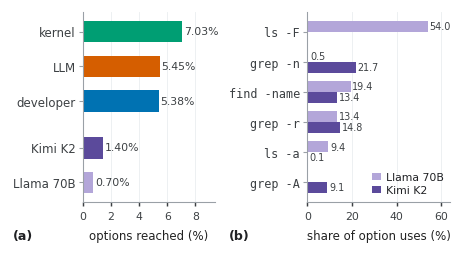

In [8]:
def load_agents():
    s = pd.read_csv(BASE / 'results' / 'agents' / 'agent_pilot_summary.csv')
    return {r.agent: {'reach_pct': r.reach_pct, 'invocations': r.invocations} for r in s.itertuples()}


def fig_agents():
    """Fig. 4: reach of the agents and of the static corpora (a), and the four
    most used options of each agent as shares of its valid option uses (b).
    Agent data: results/agents/ (section 1)."""
    plt.rcParams.update({
        'font.family': 'DejaVu Sans', 'font.size': 6.5,
        'axes.edgecolor': '#9aa0a6', 'axes.linewidth': 0.6, 'axes.labelcolor': '#222222',
        'xtick.color': '#3c4043', 'ytick.color': '#3c4043', 'text.color': '#202124',
        'axes.spines.top': False, 'axes.spines.right': False,
        'savefig.bbox': 'tight', 'pdf.fonttype': 42,
    })
    agents = load_agents()
    cnt = pd.read_csv(BASE / 'results' / 'agents' / 'agent_option_counts.csv')
    cnt = cnt[cnt.valid == 1].assign(name=lambda t: t.unit + ' ' + t.option)
    share = {a: g.set_index('name').uses / g.uses.sum() * 100 for a, g in cnt.groupby('agent')}
    AG = [('llama-70b', 'Llama 70B', '#b3a6d9'), ('kimi-k2', 'Kimi K2', '#5b4a9b')]

    fig, (axA, axB) = plt.subplots(1, 2, figsize=(3.45, 1.85), gridspec_kw={'width_ratios': [1, 1.08]})
    fig.set_constrained_layout(True)

    # (a) reach of every corpus
    rows = [('kernel', reach[('gnu', 'kernel')], C['kernel']), ('LLM', reach[('gnu', 'llm')], C['llm']),
            ('developer', reach[('gnu', 'human')], C['human'])]
    rows += [(lab, agents[a]['reach_pct'], col) for a, lab, col in AG[::-1]]
    y = np.arange(len(rows))[::-1].astype(float)
    y[3:] -= 0.35                                   # small gap between corpora and agents
    for yi, (lab, r, col) in zip(y, rows):
        axA.barh(yi, r, height=0.62, color=col, edgecolor='none', zorder=2)
        axA.text(r + 0.15, yi, f'{r:.2f}%', va='center', ha='left', fontsize=6, color='#3c4043')
    axA.set_yticks(y)
    axA.set_yticklabels([r[0] for r in rows], fontsize=6.5)
    axA.set_xlim(0, 9.4)
    axA.set_xlabel('options reached (%)', fontsize=6.5)
    axA.set_xticks([0, 2, 4, 6, 8])

    # (b) four most used options of each agent
    top = []
    for a, _, _ in AG:
        top += [o for o in share[a].sort_values(ascending=False).index[:4] if o not in top]
    top.sort(key=lambda o: -max(share[a].get(o, 0) for a, _, _ in AG))
    yb = np.arange(len(top))[::-1].astype(float)
    h = 0.36
    for k, (a, lab, col) in enumerate(AG):
        vals = [share[a].get(o, 0.0) for o in top]
        off = h / 2 if k == 0 else -h / 2
        axB.barh(yb + off, vals, height=h, color=col, edgecolor='none', zorder=2, label=lab)
        for yi, v in zip(yb + off, vals):
            if v > 0:
                axB.text(v + 0.8, yi, f'{v:.1f}', va='center', ha='left', fontsize=5.3, color='#3c4043')
    axB.set_yticks(yb)
    axB.set_yticklabels(top, fontsize=6.5, fontfamily='monospace')
    axB.set_xlim(0, 64)
    axB.set_xlabel('share of option uses (%)', fontsize=6.5)
    axB.legend(frameon=False, fontsize=6, loc='lower right', handlelength=0.9, handletextpad=0.4,
               labelspacing=0.3, borderpad=0.1)

    for ax in (axA, axB):
        ax.tick_params(axis='y', length=2, width=0.6, color='#9aa0a6', pad=2)
        ax.tick_params(axis='x', labelsize=6, length=2)
        ax.xaxis.grid(True, color='#eceff1', linewidth=0.5, zorder=0)
        ax.set_axisbelow(True)

    # panel letters at the left of each panel, on the line of its x-axis label
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    to_fig = fig.transFigure.inverted()
    for ax, letter in ((axA, '(a)'), (axB, '(b)')):
        x0 = to_fig.transform((ax.get_tightbbox(rend).x0, 0))[0]
        lab = ax.xaxis.label.get_window_extent(rend)
        y = to_fig.transform((0, (lab.y0 + lab.y1) / 2))[1]
        fig.text(x0, y, letter, ha='left', va='center', fontsize=7, fontweight='bold')
    fig.set_layout_engine('none')
    fig.savefig(FIGURES / 'agent_pilot.pdf')


fig_agents()

In [9]:
def table_topoptions(topn=10):
    """Table II: the most used options per part of the partition, as LaTeX.

    Recomputed from invocations_long.csv and the ground truth. Options are
    ranked by uses (shared: developer + LLM uses); ties are broken
    alphabetically so that the selection at the last rank is deterministic.
    """
    def name(d, unit, opt):
        u = unit.replace('_', ' ')
        if d == 'git':
            u = u[4:] if u.startswith('git ') else u
        return f'{u} {opt}'

    def tex(o):
        return r'\opt{' + o.replace('--', '-{}-') + '}'

    def ranked(d):
        cnt = {p: used[(used.dataset == d) & (used.population == p)].groupby(['unit', 'option']).size()
               for p in ('human', 'llm')}
        H, M = set(cnt['human'].index), set(cnt['llm'].index)
        assert (len(H), len(M)) == (nopt[(d, 'human')], nopt[(d, 'llm')])
        sh = sorted(((name(d, *k), int(cnt['human'][k]), int(cnt['llm'][k])) for k in H & M),
                    key=lambda t: (-(t[1] + t[2]), t[0]))[:topn]
        ho = sorted(((name(d, *k), int(cnt['human'][k])) for k in H - M), key=lambda t: (-t[1], t[0]))[:topn]
        mo = sorted(((name(d, *k), int(cnt['llm'][k])) for k in M - H), key=lambda t: (-t[1], t[0]))[:topn]
        return sh, ho, mo

    def cells(parts, i):
        sh, ho, mo = parts
        c = [tex(sh[i][0]), r'\makebox[1.5em][r]{%d}/\makebox[1.5em][l]{%d}' % sh[i][1:]] if i < len(sh) else ['', '']
        c += [tex(ho[i][0]), str(ho[i][1])] if i < len(ho) else ['', '']
        c += [tex(mo[i][0]), str(mo[i][1])] if i < len(mo) else ['', '']
        return c

    def header(d):
        return (r'\multicolumn{2}{@{}l@{}}{\textbf{%s}\enspace\textcolor{sharedcol}{Shared}}'
                r' & \multicolumn{2}{@{}l@{}}{\textcolor{devcol}{Developer only}}'
                r' & \multicolumn{2}{@{}l@{}}{\textcolor{llmcol}{LLM only}}') % DSS[d]

    def band(ds):
        parts = [ranked(d) for d in ds]
        n = max(max(len(x) for x in p) for p in parts)
        pair = r'l@{\extracolsep{0pt}\hspace{4pt}}r'
        spec = '@{}' + r'@{\extracolsep{\fill}\hspace{6pt}}'.join([pair] * (3 * len(ds))) + '@{}'
        rules = ''.join(r'\cmidrule(%s){%d-%d}' % ('r' if k == 0 else 'l', 6 * k + 1, 6 * k + 6)
                        for k in range(len(ds))) if len(ds) > 1 else r'\midrule'
        rows = ['    ' + ' & '.join(sum((cells(p, i) for p in parts), [])) + r' \\' for i in range(n)]
        return ('\\begin{tabular*}{\\textwidth}{' + spec + '}\n'
                '    \\toprule\n    ' + ' & '.join(header(d) for d in ds) + ' \\\\\n    ' + rules + '\n'
                + '\n'.join(rows) + '\n    \\bottomrule\n\\end{tabular*}\n')

    body = ('% Generated by scripts/notebooks/replication.ipynb; do not edit.\n'
            + band(['gnu', 'git']) + '\n\\vspace{6pt}\n\n' + band(['ci']))
    (FIGURES / 'table_topoptions.tex').write_text(body)
    rows = []
    for d in DS:
        sh, ho, mo = ranked(d)
        rows += [(DSS[d], 'shared', o, h, l) for o, h, l in sh]
        rows += [(DSS[d], 'developer only', o, h, 0) for o, h in ho]
        rows += [(DSS[d], 'LLM only', o, 0, l) for o, l in mo]
    pd.DataFrame(rows, columns=['dataset', 'part', 'option', 'developer_uses', 'llm_uses']) \
        .to_csv(FIGURES / 'table_topoptions.csv', index=False)


table_topoptions()
pd.read_csv(FIGURES / 'table_topoptions.csv')

,dataset,part,option,developer_uses,llm_uses
0,GNU,shared,echo -e,189,671
1,GNU,shared,rm -f,180,182
2,GNU,shared,cut -f,232,82
3,GNU,shared,mkdir -p,113,200
4,GNU,shared,cut -d,217,63
...,...,...,...,...,...
78,CI,LLM only,npm outdated --json,0,2
79,CI,LLM only,docker run -d,0,1
80,CI,LLM only,docker-compose down --remove-orphans,0,1
81,CI,LLM only,docker-compose down -v,0,1


## 4. Numbers quoted in the paper

Each line gives a number and the data it comes from, grouped by the place in the
paper where it is used.

In [10]:
# Datasets (Section III-C and Table I)
distribution = load('a7_distribution.csv').set_index(['dataset', 'population'])
units = gt.groupby('dataset').unit.nunique()
documented = gt.groupby('dataset').size()
print('units: ' + ', '.join(f'{d} {int(n)}' for d, n in units.items()) + f'  (total {int(units.sum())})')
print('documented options: ' + ', '.join(f'{d} {int(n)}' for d, n in documented.items())
      + f'  (total {int(documented.sum())})')
print('invocations: ' + ', '.join(f'{d} {POP[p]} {int(n)}' for (d, p), n in distribution.n_invocations.items())
      + f'  (total {int(distribution.n_invocations.sum())})')

prov = load('a5_provenance.csv')
repo_key = lambda r: str(r).replace('/', '_').lower()
repos = {(d, p): {repo_key(r) for r in g.repo} for (d, p), g in prov.groupby(['dataset', 'population'])}
repos[('gnu', 'kernel')] = {'torvalds_linux'}
for (d, p), r in sorted(repos.items()):
    print(f"repositories {d:3} {POP[p]:9}: {len(r)}")
print(f"distinct repositories over all corpora: {len(set().union(*repos.values()))}")

units: ci 135, git 150, gnu 118  (total 403)
documented options: ci 1864, git 5024, gnu 2716  (total 9604)
invocations: ci developer 96, ci LLM 186, git developer 564, git LLM 1268, gnu developer 4837, gnu kernel 15271, gnu LLM 8795  (total 31017)
repositories ci  developer: 28
repositories ci  LLM      : 180
repositories git developer: 48
repositories git LLM      : 364
repositories gnu developer: 25
repositories gnu kernel   : 1
repositories gnu LLM      : 264
distinct repositories over all corpora: 851


In [11]:
# RQ1: unused options, reach, invocations without options, concentration
summary = load('a1_dataset_summary.csv').set_index('dataset')
for d in ('gnu', 'git', 'ci'):
    print(f"{d}: {summary.loc[d, 'opts_union']} of {summary.loc[d, 'gt_options']} options used, "
          f"{summary.loc[d, 'never_pct']}% never used")
for (d, p), r in cov.drop_duplicates().set_index(['dataset', 'population']).iterrows():
    print(f"reach {d:3} {POP[p]:9}: {r.reach_pct:.2f}% ({int(r.opts_used)} options)")
for (d, p), r in distribution.iterrows():
    print(f"invocations without option {d:3} {POP[p]:9}: {r.pct_zero_option:.1f}%")
for _, r in load('a7_concentration.csv').iterrows():
    print(f"concentration {r.dataset:3} {POP[r.population]:9}: Gini {r.gini:.2f}, "
          f"normalised entropy {r.norm_entropy:.2f}")

gnu: 270 of 2716 options used, 90.06% never used
git: 175 of 5024 options used, 96.52% never used
ci: 38 of 1864 options used, 97.96% never used
reach ci  developer: 1.07% (20 options)
reach ci  LLM      : 1.13% (21 options)
reach git developer: 1.93% (97 options)
reach git LLM      : 2.73% (137 options)
reach gnu developer: 5.38% (146 options)
reach gnu kernel   : 7.03% (191 options)
reach gnu LLM      : 5.45% (148 options)
invocations without option ci  developer: 54.2%
invocations without option ci  LLM      : 55.9%
invocations without option git developer: 0.0%
invocations without option git LLM      : 0.0%
invocations without option gnu developer: 66.3%
invocations without option gnu kernel   : 76.0%
invocations without option gnu LLM      : 73.4%
concentration ci  developer: Gini 0.34, normalised entropy 0.93
concentration ci  LLM      : Gini 0.58, normalised entropy 0.71
concentration git developer: Gini 0.72, normalised entropy 0.68
concentration git LLM      : Gini 0.75, norma

In [12]:
# RQ2: partition of the used options (Figure 2b)
for d in ('gnu', 'git', 'ci'):
    H, M = option_set(d, 'human'), option_set(d, 'llm')
    line = f"{d}: developer only {len(H - M)}, shared {len(H & M)}, LLM only {len(M - H)}"
    if d == 'gnu':
        line += f", kernel only {len(option_set(d, 'kernel') - (H | M))}"
    print(line)

gnu: developer only 58, shared 88, LLM only 60, kernel only 64
git: developer only 38, shared 59, LLM only 78
ci: developer only 17, shared 3, LLM only 18


In [13]:
# RQ3: popularity, spelling, options per invocation
popularity = load('a2_option_popularity.csv')
for d in ('gnu', 'git'):
    g = popularity[(popularity.dataset == d) & (popularity.status == 'shared')]
    rho, pv = spearmanr(g.human_pct, g.llm_pct)
    print(f"Spearman {d}: rho = {rho:.2f} over {len(g)} shared options, p = {pv:.1e}")

al = load('a4_alias_usage_detail.csv')
al = al[(al.paired == 1) & (al.human_short + al.human_long > 0) & (al.llm_short + al.llm_long > 0)]
# A corpus prefers the short form if at least half of its uses are short (Section III-F).
prefers = lambda s, l: 'short' if s >= l else 'long'
same = [prefers(a, b) == prefers(c, e) for a, b, c, e in zip(al.human_short, al.human_long, al.llm_short, al.llm_long)]
print(f"same preferred spelling: {sum(same)} of {len(same)} aliased options "
      f"({100 * sum(same) / len(same):.0f}%), disagreements on Git: "
      f"{sum(1 for s, d in zip(same, al.dataset) if not s and d == 'git')}")
for _, r in load('a4_form_preference.csv').iterrows():
    print(f"short form share {r.dataset:3} {POP[r.population]:9}: {r.short_pct}%")

res = BASE / 'results'
depth = {('gnu', 'human'): res / 'gnu/human_invocations.csv', ('gnu', 'llm'): res / 'gnu/llm_invocations.csv',
         ('gnu', 'kernel'): res / 'gnu/coreutils_invocations.csv',
         ('ci', 'human'): res / 'ci/human_ci_invocations.csv', ('ci', 'llm'): res / 'ci/llm_ci_invocations.csv'}
for (d, p), f in depth.items():
    c = pd.read_csv(f)['option_count'].astype(int)
    print(f"two or more options {d:3} {POP[p]:9}: {100 * (c >= 2).mean():.1f}% of {len(c)} invocations")
gitraw = pd.read_csv(res / 'git/git_invocations_raw.csv')
for p in ('human', 'llm'):
    c = gitraw.loc[gitraw.group == p, 'num_options'].astype(int)
    print(f"two or more options git {POP[p]:9}: {100 * (c >= 2).mean():.1f}% of {len(c)} invocations")

Spearman gnu: rho = 0.63 over 88 shared options, p = 3.5e-11
Spearman git: rho = 0.61 over 59 shared options, p = 3.4e-07
same preferred spelling: 81 of 88 aliased options (92%), disagreements on Git: 6
short form share gnu developer: 99.3%
short form share gnu LLM      : 99.7%
short form share gnu kernel   : 99.7%
short form share git developer: 38.3%
short form share git LLM      : 62.8%
short form share ci  developer: 86.7%
short form share ci  LLM      : 90.0%
two or more options gnu developer: 9.5% of 4837 invocations
two or more options gnu LLM      : 4.6% of 8795 invocations
two or more options gnu kernel   : 4.6% of 15271 invocations
two or more options ci  developer: 18.3% of 262 invocations
two or more options ci  LLM      : 4.2% of 330 invocations
two or more options git developer: 14.7% of 556 invocations
two or more options git LLM      : 18.9% of 1236 invocations


In [14]:
# RQ4: LLM agents (Figure 4)
for _, r in pd.read_csv(res / 'agents/agent_pilot_summary.csv').iterrows():
    valid = r.distinct_options - r.invalid_distinct
    print(f"{r.agent}: {r.invocations} invocations, {r.pct_zero_option:.1f}% without option, "
          f"{valid} valid options, reach {r.reach_pct:.2f}%")
counts = pd.read_csv(res / 'agents/agent_option_counts.csv')
counts = counts[counts.valid == 1].assign(name=lambda t: t.unit + ' ' + t.option)
for a, g in counts.groupby('agent'):
    top = g.sort_values('uses', ascending=False).head(3)
    print(f"{a}: top options " + ', '.join(f"{n} {100 * u / g.uses.sum():.1f}%" for n, u in zip(top.name, top.uses)))

llama-70b: 1802 invocations, 29.4% without option, 19 valid options, reach 0.70%
kimi-k2: 14370 invocations, 28.2% without option, 38 valid options, reach 1.40%
kimi-k2: top options grep -n 21.7%, grep -r 14.8%, find -name 13.4%
llama-70b: top options ls -F 54.0%, find -name 19.4%, grep -r 13.4%


In [15]:
# Threats to validity
lc = load('a4_logical_coverage.csv').set_index('dataset')
print(f"GNU LLM reach with aliases collapsed: {100 * lc.loc['gnu', 'llm_logical'] / lc.loc['gnu', 'gt_logical_options']:.2f}%")
ci_files = inv[inv.dataset == 'ci'].groupby('population').file.nunique()
print(f"CI workflows that invoke docker, npm, or pip: LLM {ci_files['llm']} of 210, developer {ci_files['human']} of 210")
samples = load('a8_file_subsampling.csv')
for _, r in samples[samples.dataset.isin(['gnu', 'git'])].iterrows():
    print(f"90% file samples {r.dataset:3} {POP[r.population]:9}: {100 * r.options_90 / r.options_100:.1f}% of the options")

GNU LLM reach with aliases collapsed: 7.54%
CI workflows that invoke docker, npm, or pip: LLM 60 of 210, developer 31 of 210
90% file samples gnu developer: 95.6% of the options
90% file samples gnu LLM      : 96.2% of the options
90% file samples gnu kernel   : 95.1% of the options
90% file samples git developer: 94.7% of the options
90% file samples git LLM      : 96.1% of the options


## 5. Check of the analysis tables

A second implementation in pandas recomputes the tables in `results/analysis/`
from the foundation tables (`invocations_long.csv` and `groundtruth_long.csv`)
and compares the values. Two CI values differ: `a7_distribution.csv` counts one
more LLM CI invocation without options than `invocations_long.csv` (55.91%
instead of 55.38%, and 0.527 instead of 0.532 options per invocation), which
only affects that label in Figure 1b.

In [16]:
def check_tables():
    inv = pd.read_csv(AN / 'invocations_long.csv', keep_default_na=False)
    gt = pd.read_csv(AN / 'groundtruth_long.csv', keep_default_na=False)
    gt_set = set(map(tuple, gt[['dataset', 'unit', 'option']].values))
    uses = inv[inv.option != ''].copy()
    uses['valid'] = [t in gt_set for t in map(tuple, uses[['dataset', 'unit', 'option']].values)]
    differences = []

    def check(name, got, want, tol=0.0):
        ok = (abs(got - want) <= tol) if isinstance(want, float) else (got == want)
        print(f"[{'OK' if ok else 'DIFF'}] {name}: recomputed {got}, table {want}")
        if not ok:
            differences.append(name)

    # a1_dataset_summary
    a1 = pd.read_csv(AN / 'a1_dataset_summary.csv').set_index('dataset')
    for ds in ['gnu', 'git', 'ci']:
        g = gt[gt.dataset == ds]
        u = uses[(uses.dataset == ds) & uses.valid]
        union = u.drop_duplicates(['unit', 'option']).shape[0]
        never = len(g) - union
        check(f'{ds} gt_options', len(g), int(a1.loc[ds, 'gt_options']))
        check(f'{ds} gt_units', g.unit.nunique(), int(a1.loc[ds, 'gt_units']))
        check(f'{ds} opts_union', union, int(a1.loc[ds, 'opts_union']))
        check(f'{ds} never_pct', round(100 * never / len(g), 2), float(a1.loc[ds, 'never_pct']), tol=0.005)

    # a1_population_coverage and a1_human_llm_split
    coverage = pd.read_csv(AN / 'a1_population_coverage.csv')
    for _, r in coverage.iterrows():
        u = uses[(uses.dataset == r.dataset) & (uses.population == r.population) & uses.valid]
        n = u.drop_duplicates(['unit', 'option']).shape[0]
        gtn = (gt.dataset == r.dataset).sum()
        check(f'{r.dataset}/{r.population} opts_used', n, int(r.opts_used))
        check(f'{r.dataset}/{r.population} reach_pct', round(100 * n / gtn, 2), float(r.reach_pct), tol=0.005)
        units = inv[(inv.dataset == r.dataset) & (inv.population == r.population)].unit.nunique()
        check(f'{r.dataset}/{r.population} units_used', units, int(r.units_used))
    split = pd.read_csv(AN / 'a1_human_llm_split.csv').set_index('dataset')
    for ds in ['gnu', 'git', 'ci']:
        h = set(map(tuple, uses[(uses.dataset == ds) & (uses.population == 'human') & uses.valid][['unit', 'option']].values))
        m = set(map(tuple, uses[(uses.dataset == ds) & (uses.population == 'llm') & uses.valid][['unit', 'option']].values))
        check(f'{ds} shared', len(h & m), int(split.loc[ds, 'shared']))
        check(f'{ds} human_only', len(h - m), int(split.loc[ds, 'human_only']))
        check(f'{ds} llm_only', len(m - h), int(split.loc[ds, 'llm_only']))

    # a7_distribution, a7_validity, a7_concentration
    for _, r in pd.read_csv(AN / 'a7_distribution.csv').iterrows():
        sub = inv[(inv.dataset == r.dataset) & (inv.population == r.population)]
        zero = (sub.option == '').sum()
        n_opts = (sub.option != '').sum()
        check(f'{r.dataset}/{r.population} pct_zero', round(100 * zero / r.n_invocations, 2),
              float(r.pct_zero_option), tol=0.011)
        check(f'{r.dataset}/{r.population} mean_options', round(n_opts / r.n_invocations, 3),
              float(r.mean_options), tol=0.0011)
    for _, r in pd.read_csv(AN / 'a7_validity.csv').iterrows():
        sub = uses[(uses.dataset == r.dataset) & (uses.population == r.population)]
        check(f'{r.dataset}/{r.population} occurrences', len(sub), int(r.opt_occurrences))
        check(f'{r.dataset}/{r.population} invalid_pct', round(100 * (~sub.valid).sum() / len(sub), 2),
              float(r.invalid_pct), tol=0.005)
        check(f'{r.dataset}/{r.population} distinct_invalid',
              sub[~sub.valid].drop_duplicates(['unit', 'option']).shape[0], int(r.distinct_invalid_options))

    def gini(c):
        c = np.sort(np.asarray(c, float))
        n = len(c)
        return (2 * np.sum(np.arange(1, n + 1) * c) / (n * c.sum())) - (n + 1) / n

    for _, r in pd.read_csv(AN / 'a7_concentration.csv').iterrows():
        sub = uses[(uses.dataset == r.dataset) & (uses.population == r.population) & uses.valid]
        c = sub.groupby(['unit', 'option']).size()
        check(f'{r.dataset}/{r.population} gini', round(gini(c.values), 3), float(r.gini), tol=0.0011)
        check(f'{r.dataset}/{r.population} n_options_used', len(c), int(r.n_options_used))

    # a6_cooccurrence (number of option pairs per corpus)
    edges = pd.read_csv(AN / 'a6_cooccurrence.csv').groupby(['dataset', 'population']).size()
    for (ds, p), want in [(('gnu', 'human'), 137), (('gnu', 'llm'), 189), (('git', 'human'), 55),
                          (('git', 'llm'), 87), (('ci', 'human'), 44), (('ci', 'llm'), 9)]:
        check(f'{ds}/{p} cooc_edges', int(edges.get((ds, p), 0)), want)

    if differences:
        print(f'\n{len(differences)} values differ: ' + ', '.join(differences))
    else:
        print('\nAll values agree.')


check_tables()

[OK] gnu gt_options: recomputed 2716, table 2716


[OK] gnu gt_units: recomputed 118, table 118
[OK] gnu opts_union: recomputed 270, table 270
[OK] gnu never_pct: recomputed 90.06, table 90.06
[OK] git gt_options: recomputed 5024, table 5024
[OK] git gt_units: recomputed 150, table 150
[OK] git opts_union: recomputed 175, table 175
[OK] git never_pct: recomputed 96.52, table 96.52
[OK] ci gt_options: recomputed 1864, table 1864
[OK] ci gt_units: recomputed 135, table 135
[OK] ci opts_union: recomputed 38, table 38
[OK] ci never_pct: recomputed 97.96, table 97.96
[OK] ci/human opts_used: recomputed 20, table 20
[OK] ci/human reach_pct: recomputed 1.07, table 1.07
[OK] ci/human units_used: recomputed 23, table 23
[OK] ci/llm opts_used: recomputed 21, table 21
[OK] ci/llm reach_pct: recomputed 1.13, table 1.13


[OK] ci/llm units_used: recomputed 25, table 25
[OK] git/human opts_used: recomputed 97, table 97
[OK] git/human reach_pct: recomputed 1.93, table 1.93
[OK] git/human units_used: recomputed 22, table 22
[OK] git/llm opts_used: recomputed 137, table 137
[OK] git/llm reach_pct: recomputed 2.73, table 2.73


[OK] git/llm units_used: recomputed 21, table 21
[OK] gnu/human opts_used: recomputed 146, table 146
[OK] gnu/human reach_pct: recomputed 5.38, table 5.38
[OK] gnu/human units_used: recomputed 62, table 62
[OK] gnu/kernel opts_used: recomputed 191, table 191
[OK] gnu/kernel reach_pct: recomputed 7.03, table 7.03
[OK] gnu/kernel units_used: recomputed 73, table 73
[OK] gnu/llm opts_used: recomputed 148, table 148
[OK] gnu/llm reach_pct: recomputed 5.45, table 5.45
[OK] gnu/llm units_used: recomputed 64, table 64


[OK] gnu shared: recomputed 88, table 88
[OK] gnu human_only: recomputed 58, table 58
[OK] gnu llm_only: recomputed 60, table 60
[OK] git shared: recomputed 59, table 59
[OK] git human_only: recomputed 38, table 38
[OK] git llm_only: recomputed 78, table 78


[OK] ci shared: recomputed 3, table 3
[OK] ci human_only: recomputed 17, table 17
[OK] ci llm_only: recomputed 18, table 18
[OK] ci/human pct_zero: recomputed 54.17, table 54.17
[OK] ci/human mean_options: recomputed 0.979, table 0.979
[DIFF] ci/llm pct_zero: recomputed 55.38, table 55.91
[DIFF] ci/llm mean_options: recomputed 0.532, table 0.527
[OK] git/human pct_zero: recomputed 0.0, table 0.0
[OK] git/human mean_options: recomputed 1.179, table 1.179
[OK] git/llm pct_zero: recomputed 0.0, table 0.0
[OK] git/llm mean_options: recomputed 1.2, table 1.2
[OK] gnu/human pct_zero: recomputed 66.28, table 66.28
[OK] gnu/human mean_options: recomputed 0.449, table 0.449
[OK] gnu/kernel pct_zero: recomputed 75.95, table 75.95
[OK] gnu/kernel mean_options: recomputed 0.295, table 0.295
[OK] gnu/llm pct_zero: recomputed 73.36, table 73.36
[OK] gnu/llm mean_options: recomputed 0.344, table 0.344
[OK] ci/human occurrences: recomputed 94, table 94
[OK] ci/human invalid_pct: recomputed 57.45, tabl

[OK] ci/human gini: recomputed 0.34, table 0.34
[OK] ci/human n_options_used: recomputed 20, table 20


[OK] ci/llm gini: recomputed 0.582, table 0.582
[OK] ci/llm n_options_used: recomputed 21, table 21
[OK] git/human gini: recomputed 0.72, table 0.72
[OK] git/human n_options_used: recomputed 97, table 97
[OK] git/llm gini: recomputed 0.752, table 0.752
[OK] git/llm n_options_used: recomputed 137, table 137
[OK] gnu/human gini: recomputed 0.755, table 0.755
[OK] gnu/human n_options_used: recomputed 146, table 146
[OK] gnu/llm gini: recomputed 0.759, table 0.759
[OK] gnu/llm n_options_used: recomputed 148, table 148
[OK] gnu/human cooc_edges: recomputed 137, table 137
[OK] gnu/llm cooc_edges: recomputed 189, table 189
[OK] git/human cooc_edges: recomputed 55, table 55
[OK] git/llm cooc_edges: recomputed 87, table 87
[OK] ci/human cooc_edges: recomputed 44, table 44
[OK] ci/llm cooc_edges: recomputed 9, table 9

2 values differ: ci/llm pct_zero, ci/llm mean_options
